# Entrega Final
**Software Matemático y Estadístico** 

**Autor:** Jon Lorenzo Insausti  
**Fecha:** 23/10/2026

## Introducción

Este documento es uno de los dos archivos que componen la parte correspondiente al lenguaje de programación Python de la entrega evaluable de la asignatura de Software Matemático y Estadístico. En él, se ilustra el uso de las distintas funciones con las que se ha trabajado a lo largo de la asignatura. Estas funciones, en su mayoría básicas, se explican de manera detallada en el otro documento de la entrega, tanto en lo referente a su código interno cómo a lo relacionado con las entradas y salidas correspondientes a cada una de ellas. Ese otro documento, llamado `Funciones`, es un archivo.py al que se accede en el siguiente bloque de código, con tal de poder llamar posteriormente a las funciones en el presentes. Además de este archivo, para ejecuta correctamente este notebook, serán necesarias las siguientes tres librerias: Numpy, panmdas y Matplotlib. 

En este notebook, se muestra el funcionamiento de las funciones creadas de manera más general. Para ordenar las funciones de una manera adecuada, se ha optado por seguir el mismo orden que sigue la asignatura con los documentos explicativos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gestion_datasets.Funciones import (
    discretizeEW, discretizeEF, discretize_dataset,
    varianza, entropia, entropia_normalizada,
    AUC, plot_AUC, calculodemetricas, calculodemetricas_umbral,
    normalizacion, estandarizacion, normalizacion_dataset, estandarizacion_dataset,
    covarianza, correlacion_pearson, inf_mutua, matriz_correlacion, plot_correlacion
)

## Funciones de discretización
Las primeras funciones con las que se ha trabajado en esta asignatura son aquellas relacionadas con los algoritmos de discretización. Estos algoritmos de discretización permiten discretizar una serie de datos en paquetes o grupos más pequeños. Existen dos formas principales de realizar dicha clasificación, dependiendo de la caracteristica compartida por los distintos grupos: los algoritmos de discretización de **igual anchura** y los de **igual frecuencia**.

Para explicar el funcionamiento de ambos, utilizaremos el mismo atributo, un vector numérico llamado x:

In [2]:
x=[2,3,1,4,1,3,4.5,2.8,8,9,-2,0]
x

[2, 3, 1, 4, 1, 3, 4.5, 2.8, 8, 9, -2, 0]

### Igual anchura (EW)
Si queremos discretizar los valores de x en paquetes con la misma distancia entre el mínimo y el máximo, es decir, en grupos de igual anchura, emplearemos la función `discretizeEW`   (EqualWidth). Esta funcion tiene dos entradas: el atributo a discretizar y el numero de grupos que debe generar. Con estos dos inputs, la función devuelve un resultado en forma de lista y con tres componentes. Por un lado, está la `solucion`, que consiste en una secuencia de intervalos, uno por cada elemento del vector original. Cada intervalo indica a qué grupo pertenece el valor correspondiente y cuáles son los límites de dicho grupo. Además, debajo de la clasificación del vector se muestran los grupos o níveles diferentes en los que se han discretizado los valores, denominados `etiquetas`.

In [3]:
Discretizacion_EW=discretizeEW(x,2)
print('Intervalos asignados:')
print(Discretizacion_EW['solucion'])
print('Etiquetas:')
print(Discretizacion_EW['etiquetas'])

Intervalos asignados:
['(-inf,3.5]', '(-inf,3.5]', '(-inf,3.5]', '(3.5,inf)', '(-inf,3.5]', '(-inf,3.5]', '(3.5,inf)', '(-inf,3.5]', '(3.5,inf)', '(3.5,inf)', '(-inf,3.5]', '(-inf,3.5]']
Etiquetas:
['I1', 'I1', 'I1', 'I2', 'I1', 'I1', 'I2', 'I1', 'I2', 'I2', 'I1', 'I1']


Por último, están los `limites`, un vector con una serie de puntos que sirven para delimitar los grupos.

In [4]:
Discretizacion_EW['limites']

[-inf, 3.5, inf]

### Igual frecuencia (EF)

En cambio, si optamos por discretizar nuestro vector en grupos con el mismo número de individuos, sin que estos grupos deban tener la misma distancia entre su mínimo y su máximo, usaremos la función `discretizeEF` (Equal Frequency). Las entradas vuelven a ser el vector a discretizar y el número de paquetes deseado, pero las salidas varían. Esta función devuelve una lista con tres elementos. Por un lado la `solucion`, con el intervalo correspondiente a cada individuo en su respectiva posición, sin el límite de cada intervalo debido a que en este caso un mismo valor límite puede caer en dos intervalos distintos. Por otro las `etiquetas`, que indican a que intervalo pertenece cada individuo, y por último, los `limites` de cada grupo/intervalo.

En caso de empate, si hay valores iguales en los límites de los grupos, la implementación puede repartirlos entre grupos diferentes para mantener las frecuencias.

In [5]:
Discretizacion_EF=discretizeEF(x,2)
print('Intervalos asignados:')
print(Discretizacion_EF['solucion'])
print('Etiquetas/grupos:')
print(Discretizacion_EF['etiquetas'])
print('Limites:')
print(Discretizacion_EF['limites'])

Intervalos asignados:
['(-inf,2.8]', '(2.8,inf)', '(-inf,2.8]', '(2.8,inf)', '(-inf,2.8]', '(2.8,inf)', '(2.8,inf)', '(-inf,2.8]', '(2.8,inf)', '(2.8,inf)', '(-inf,2.8]', '(-inf,2.8]']
Etiquetas/grupos:
['I1', 'I2', 'I1', 'I2', 'I1', 'I2', 'I2', 'I1', 'I2', 'I2', 'I1', 'I1']
Limites:
[-inf, 2.8, inf]


### Discretización de un dataset
Estos dos algoritmos de discretización también se pueden adaptar para discretizar un grupo de atributos, tales como un dataset.
Al contrario que en R, Python se utiliza la misma función `discretize_dataset()`: `anchura=True` selecciona EW y `anchura=False` selecciona EF. Las columnas no numéricas se mantienen en el dataset sin cambios. Véase aquí un ejemplo con el siguiente dataset, discretizado en tres grupos diferentes con cada uno de los métodos anteriormente explicados:

In [6]:
Dataset=pd.DataFrame({
    'altura':[1.68,1.72,1.75,1.80,1.77,1.77,1.82,1.70,1.74,1.88,1.69,1.76],
    'peso':[62,68,72,80,59,75,84,66,70,90,64,95]
})
Dataset

,altura,peso
0,1.68,62
1,1.72,68
2,1.75,72
3,1.80,80
4,1.77,59
5,1.77,75
6,1.82,84
7,1.70,66
8,1.74,70
9,1.88,90


In [7]:
Dataset_discretizado_por_anchura=discretize_dataset(Dataset,3,anchura=True)
Dataset_discretizado_por_frecuencia=discretize_dataset(Dataset,3,anchura=False)

print('Dataset discretizado por igual anchura:')
display(Dataset_discretizado_por_anchura['solucion'])
print('Dataset discretizado por igual frecuencia:')
display(Dataset_discretizado_por_frecuencia['solucion'])

Dataset discretizado por igual anchura:


,altura,peso
0,"(-inf,1.7466666666666666]","(-inf,71.0]"
1,"(-inf,1.7466666666666666]","(-inf,71.0]"
2,"(1.7466666666666666,1.8133333333333332]","(71.0,83.0]"
3,"(1.7466666666666666,1.8133333333333332]","(71.0,83.0]"
4,"(1.7466666666666666,1.8133333333333332]","(-inf,71.0]"
5,"(1.7466666666666666,1.8133333333333332]","(71.0,83.0]"
6,"(1.8133333333333332,inf)","(83.0,inf)"
7,"(-inf,1.7466666666666666]","(-inf,71.0]"
8,"(-inf,1.7466666666666666]","(-inf,71.0]"
9,"(1.8133333333333332,inf)","(83.0,inf)"


Dataset discretizado por igual frecuencia:


,altura,peso
0,"(-inf,1.72]","(-inf,66]"
1,"(-inf,1.72]","(66,75]"
2,"(1.72,1.77]","(66,75]"
3,"(1.77,inf)","(75,inf)"
4,"(1.72,1.77]","(-inf,66]"
5,"(1.77,inf)","(66,75]"
6,"(1.77,inf)","(75,inf)"
7,"(-inf,1.72]","(-inf,66]"
8,"(1.72,1.77]","(66,75]"
9,"(1.77,inf)","(75,inf)"


Si queremos comparar los resultados de ambos algoritmos, simplemente debemos hacer lo siguiente para ver en que intervalo ordena cada algoritmo cada individuo, primero por altura y luego por peso. Para ello, se muestran las **etiquetas** de intervalo de ambas discretizaciones, primero por altura y después por peso. Para acceder a las mismas, se escribe `resultado['etiquetas']['nombre_columna']`:

In [8]:
print('Altura con EW y EF, respectivamente')
print(Dataset_discretizado_por_anchura['etiquetas']['altura'])
print(Dataset_discretizado_por_frecuencia['etiquetas']['altura'])

print('Peso con EW y EF, respectivamente')
print(Dataset_discretizado_por_anchura['etiquetas']['peso'])
print(Dataset_discretizado_por_frecuencia['etiquetas']['peso'])

Altura con EW y EF, respectivamente
['I1', 'I1', 'I2', 'I2', 'I2', 'I2', 'I3', 'I1', 'I1', 'I3', 'I1', 'I2']
['I1', 'I1', 'I2', 'I3', 'I2', 'I3', 'I3', 'I1', 'I2', 'I3', 'I1', 'I2']
Peso con EW y EF, respectivamente
['I1', 'I1', 'I2', 'I2', 'I1', 'I2', 'I3', 'I1', 'I1', 'I3', 'I1', 'I3']
['I1', 'I2', 'I2', 'I3', 'I1', 'I2', 'I3', 'I1', 'I2', 'I3', 'I1', 'I3']


## Cálculo de métricas

Una vez implementados los métodos de discretización, se analizan los atributos del siguiente dataset con distintas métricas. Las variables **numéricas** se evalúan mediante la varianza y, cuando se dispone de una clase binaria especificada, también mediante el AUC. Las variables **categóricas** se evalúan mediante la entropía. Para ello, se emplea la función `calculodemetricas`, que toma como entrada todo el dataset, y calcula una métrica u otra dependiendo de la clase de la variable.

Como ejemplo, se utiliza el mismo dataset que en el documento de R. La columna `Sexo` se representa mediante categorías de texto y `Deporte` mediante valores booleanos (`True` y `False`).

In [9]:
df=pd.DataFrame({
    'ID':[str(i) for i in range(1,13)],
    'Nombre':['Jon','Gorka','Ane','Maren','Irati','Markel','Jon','Ane','Pedro','Irati','Inigo','Aitor'],
    'Sexo':pd.Categorical(['M','M','F','F','F','M','M','F','M','F','M','M']),
    'Edad':[18,23,64,27,23,31,54,23,45,33,72,20],
    'Altura':[1.78,1.82,1.65,1.70,1.68,1.84,1.76,1.72,1.79,1.66,1.73,1.81],
    'Peso':[72,91,67,63,59,86,78,65,84,61,74,76],
    'MasaMuscular' :[40,36,32,37,34,42,39,35,38,37,33,41],
    'Deporte':[True,False,False,True,False,True,True,True,False,True,False,True]
})
df

,ID,Nombre,Sexo,Edad,Altura,Peso,MasaMuscular,Deporte
0,1,Jon,M,18,1.78,72,40,True
1,2,Gorka,M,23,1.82,91,36,False
2,3,Ane,F,64,1.65,67,32,False
3,4,Maren,F,27,1.70,63,37,True
4,5,Irati,F,23,1.68,59,34,False
5,6,Markel,M,31,1.84,86,42,True
6,7,Jon,M,54,1.76,78,39,True
7,8,Ane,F,23,1.72,65,35,True
8,9,Pedro,M,45,1.79,84,38,False
9,10,Irati,F,33,1.66,61,37,True


La función `calculodemetricas` incluye las funciones para el calculo de la **varianza**, **AUC** y **entropía**, que se explican a continuación.


La varianza muestral, que mide la dispersión de una variable numérica respecto a su media, se calcula mediante la siguiente fórmula:

$$
\operatorname{Var}(X)=s^2=\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}
$$

Donde $x_i$ es el valor de cada individuo, $\bar{x}$ la media de los valores de la variable y $n$ el número de individuos. En este caso, al ser la varianza muestral, el denominador es $n-1$, ya que se considera que los datos analizados son una muestra de la población total. Dicha varianza muestral se calcula con la función `varianza`. He aquí un ejemplo con la variable **Edad** del dataset:

In [10]:
print('Varianza de la Edad:',varianza(list(df['Edad'])))

Varianza de la Edad: 335.17424242424244


Además, si en la entrada se ha especificado una variable clase binaria, se evaluará el AUC de los atributos numéricos mediante la función `AUC`. Esta es una métrica que sirve para evaluar la capacidad de una variable numérica para diferenciar entre dos clases.Para obtenerla, primero se calculan la tasa de verdaderos positivos **TPR** y la de falsos positivos **FPR** para cada individuo o punto de corte de la variable analizada. Al representar estos puntos con la TPR en el eje Y y la FPR en el eje X, se obtiene la **curva ROC**. 

El **AUC** no es más que el área debajo de la curva, y cuanto más se acerque a 1, mayor será la capacidad de la variable para distinguir correctamente entre las dos clases. Un valor cercano a 0,5 indica que la variable apenas tiene capacidad de discriminación, mientras que un valor cercano a 0 indica que la variable presenta una capacidad de discriminación inversa, es decir, que valores altos y bajos de la variable están asociados a la clase contraria de la esperada. A continuación se ha calculado el **AUC** con la variable numérica `Edad`y la variable lógica `Deporte`, donde clase positiva es `True:

In [11]:
resultado_auc=AUC(list(df['Edad']),list(df['Deporte']))
resultado_auc

AUC: 0.2857142857142857


{'auc': 0.2857142857142857,
 'FPR': [0.0, 0.2, 0.4, 0.4, 0.6, 0.6, 0.6, 0.6, 1.0, 1.0, 1.0],
 'TPR': [0.0,
  0.0,
  0.0,
  0.14285714285714285,
  0.14285714285714285,
  0.2857142857142857,
  0.42857142857142855,
  0.5714285714285714,
  0.7142857142857143,
  0.8571428571428571,
  1.0]}

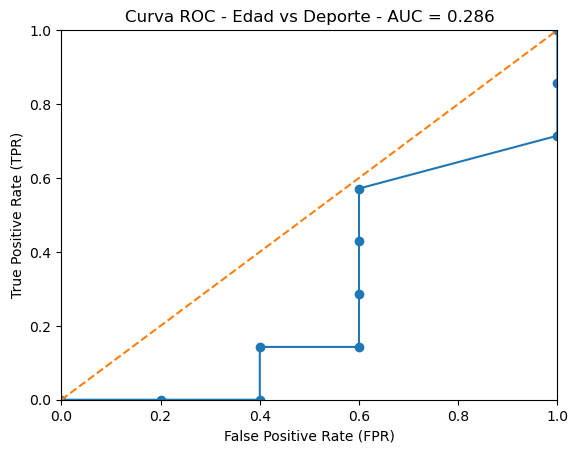

In [12]:
plot_AUC(resultado_auc,'Edad','Deporte')

Si la variable es discreta, se calcula la entropia de Shannon de la misma con la función `entropia`. Esta métrica sirve para medir el grado de heterogeneidad de una variable discreta o categórica. Para ello, primero se estima la probabilidad que tiene cada valor tomando en cuenta el número de apariciones en el vector. Después se aplica la ecuación de la entropía:

$$
H(X)=-\sum_{i=1}^{k}p_i\log_2(p_i),\qquad p_i=\frac{n_i}{n}
$$

Donde $k$ es el número de valores distintos y $p_i$ es la probabilidad asociada a cada valor único de la variable, que se obtiene de la siguiente manera:

In [13]:
print('Entropia de Sexo:',entropia(list(df['Sexo'])))

Entropia de Sexo: 0.9798687566511528


### Métricas para todas las variables

`calculodemetricas()` identifica automáticamente las columnas numéricas o categóricas, imprime la varianza o la entropía según corresponda y, si se especifica una clase binaria, calcula y representa el AUC de cada variable numérica. En este caso, se ha elegido 'Deporte' como dicha clase binaria.

Variable: ID
Entropia: 3.584962500721156
Variable: Nombre
Entropia: 3.0849625007211556
Variable: Sexo
Entropia: 0.9798687566511528
Variable: Edad
Varianza: 335.17424242424244
AUC: 0.2857142857142857


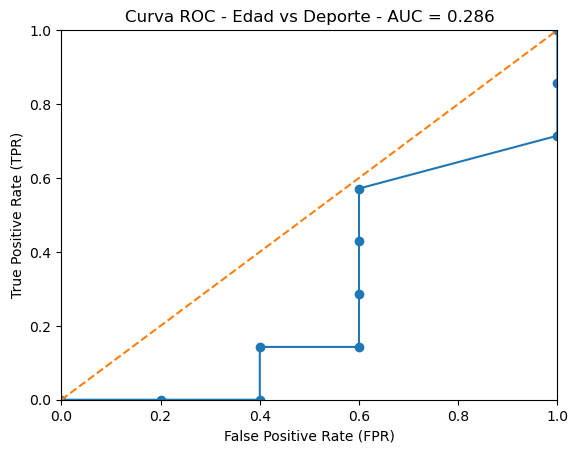

Variable: Altura
Varianza: 0.004154545454545462
AUC: 0.5714285714285714


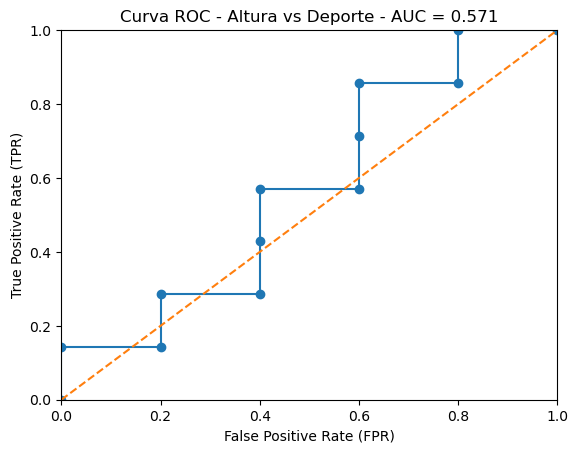

Variable: Peso
Varianza: 108.18181818181819
AUC: 0.42857142857142855


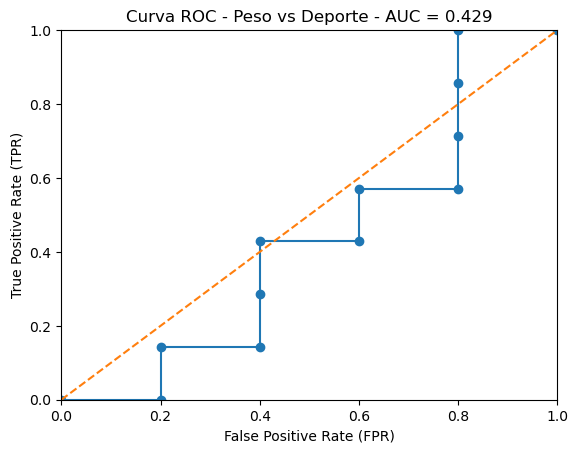

Variable: MasaMuscular
Varianza: 10.0
AUC: 0.8857142857142857


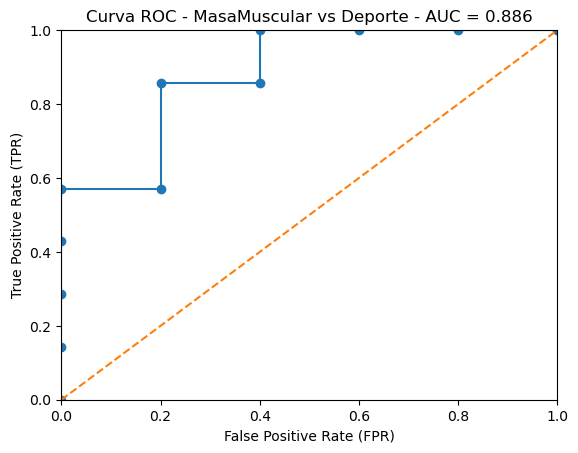

In [14]:
calculodemetricas(df,'Deporte')

### Filtrado de variables mediante umbrales

El cálculo de métricas como la varianza, la entropía o el AUC también puede ser utilizado como forma de filtrar variables dentro de un dataset. Es decir, un nuevo dataset puede ser creado a partir de las variables del original que cumplan ciertos requisitos, como por ejemplo, superar un cierto valor de **varianza, AUC** o **entropía**.

Para aplicar este umbral, se ha modificado la función anterior, creando `calculodemetricas_umbral`, a la que se le suma como entrada un parámetro llamado `umbral`, que contiene un valor mínimo para cada métrica, en el siguiente orden : varianza, AUC y entropía. Cabe puntualizar que para simplificar el uso,los umbrales del AUC y de la entropía deben ser números del 0 al 1, ya que en este caso la entropía se normaliza. Sin embargo, el umbral de la varianza puede tomar cualquier valor mayor o igual que cero. De esta forma, la función devuelve un nuevo dataset con las variables que han pasado el corte, tal y como se da en R:

Variable: ID
Entropia: 1.0
Variable: Nombre
Entropia: 0.973197315178593
Variable: Sexo
Entropia: 0.9798687566511528
Variable: Edad
Varianza: 335.17424242424244
AUC: 0.2857142857142857


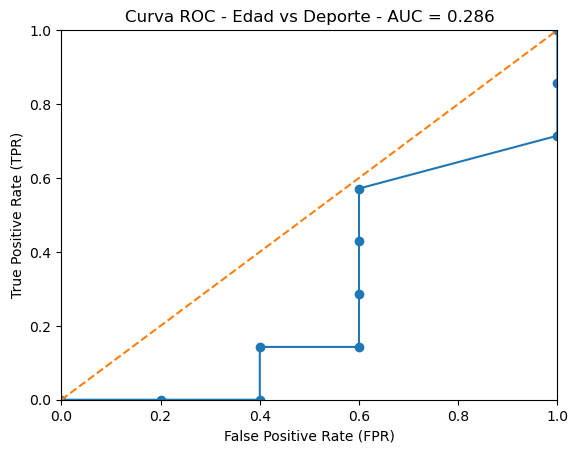

Variable: Altura
Varianza: 0.004154545454545462
AUC: 0.5714285714285714


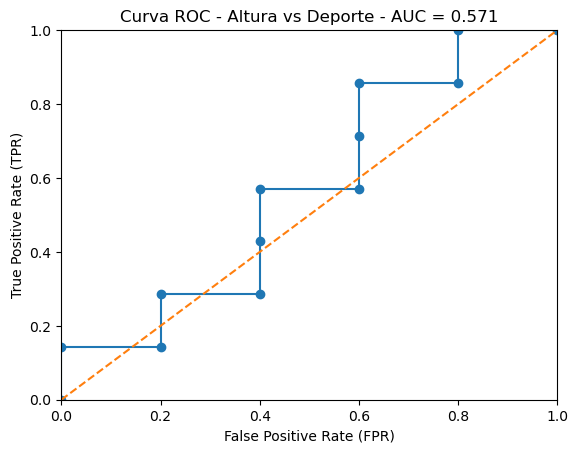

Variable: Peso
Varianza: 108.18181818181819
AUC: 0.42857142857142855


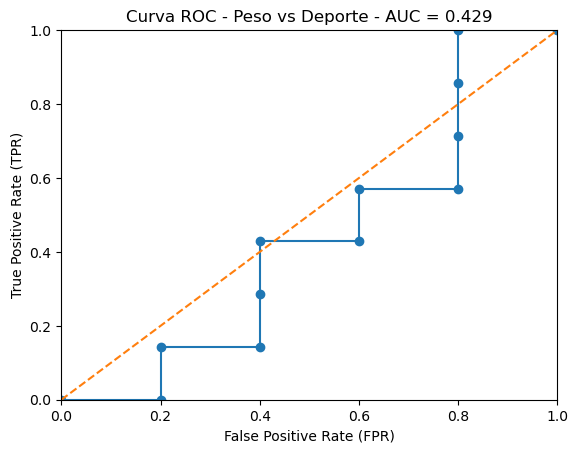

Variable: MasaMuscular
Varianza: 10.0
AUC: 0.8857142857142857


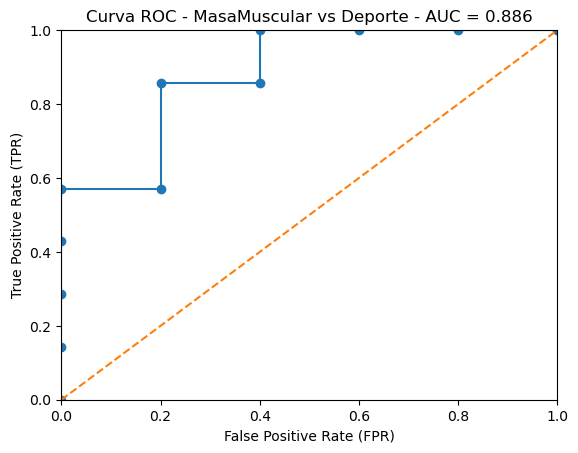

,ID,Peso,MasaMuscular
0,1,72,40
1,2,91,36
2,3,67,32
3,4,63,37
4,5,59,34
5,6,86,42
6,7,78,39
7,8,65,35
8,9,84,38
9,10,61,37


In [15]:
umbral=(0.3,0.3,1)
df1=calculodemetricas_umbral(df,'Deporte',umbral)
df1

Puede darse el caso en el que ninguna variable supere los umbrales fijados por el usuario. En este caso, se devuelve el dataset vacio, o, como es el caso del ejemplo, la columna que sirve de indicador de cada individuo.

## Normalización y estandarización

Además del cálculo de métricas como la varianza o la entropía, es común la realización de transformaciones sobre las distintas variables, a fin de llevar todas a un mismo rango. Las dos transformaciones más típicas son la **normalización** y la **estandarización**. 

### Normalización de un atributo

En la normalización, el objetivo es realizar un desplazamiento y un escalado de los valores, con tal de que el valor mínimo de los datos de la variable sea 0, y el máximo 1. Dicha normalización se consigue restando el mínimo del vector a cada valor del mismo, y dividiendo el resultado por la distancia entre el máximo y el mínimo:
$$
x'_i=\frac{x_i-\min(x)}{\max(x)-\min(x)}
$$

Para ello, se puede utilizar la función `normalizacion`, que toma como entrada un vector y lo devuelve normalizado. Cuando todos los valores son iguales, la implementación devuelve ceros para evitar dividir entre cero.

In [16]:
print('Vector original:',x)
print('Normalizacion:',normalizacion(x))

Vector original: [2, 3, 1, 4, 1, 3, 4.5, 2.8, 8, 9, -2, 0]
Normalizacion: [0.36363636363636365, 0.45454545454545453, 0.2727272727272727, 0.5454545454545454, 0.2727272727272727, 0.45454545454545453, 0.5909090909090909, 0.43636363636363634, 0.9090909090909091, 1.0, 0.0, 0.18181818181818182]


### Estandarización de un atributo

En la estandarización, se asume que los datos de la variable cumplen una distribución gaussiana, y se busca cambiar el centro de los datos para que convertir los valores estandarizados en desviaciones respecto a su media, expresadas en unidades de desviación típica. Esto se consigue restando la media a cada valor del vector y dividiendo el resultado por la desviación típica: 

$$
z_i=\frac{x_i-\bar{x}}{s}
$$

El vector resultante tiene media 0 y desviación típica muestral 1, siempre que la variabilidad de los datos sea positiva. No es necesario suponer que los datos siguen una distribución gaussiana para aplicar esta transformación. 

In [17]:
print('Estandarizacion:',estandarizacion(x))

Estandarizacion: [np.float64(-0.3282129898263419), np.float64(-0.008005194873813189), np.float64(-0.6484207847788706), np.float64(0.3122026000787155), np.float64(-0.6484207847788706), np.float64(-0.008005194873813189), np.float64(0.47230649755497983), np.float64(-0.07204675386431898), np.float64(1.59303377988883), np.float64(1.9132415748413587), np.float64(-1.6090441696364568), np.float64(-0.9686285797313993)]


### Normalización y estandarización de datasets

Tanto la normalización como la estandarización pueden realizarse para datasets completos, siempre y cuando sus variables sean numéricas. Las funciones `normalizacion_dataset` y `estandarizacion_dataset` llevan a cabo esta práctica, tomando el dataset original como entrada y devolviendo el dataset normalizado o estandarizado como salida. Las columnas no numéricas permanecen en el resultado sin cambios.

In [18]:
print('Dataset normalizado:')
display(normalizacion_dataset(df))
print('Dataset estandarizado:')
display(estandarizacion_dataset(df))

Dataset normalizado:
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin modificar.
La variable no es numerica. Se devuelve sin 

,ID,Nombre,Sexo,Edad,Altura,Peso,MasaMuscular,Deporte
0,1,Jon,M,0.000000,0.684211,0.40625,0.8,True
1,2,Gorka,M,0.092593,0.894737,1.00000,0.4,False
2,3,Ane,F,0.851852,0.000000,0.25000,0.0,False
3,4,Maren,F,0.166667,0.263158,0.12500,0.5,True
4,5,Irati,F,0.092593,0.157895,0.00000,0.2,False
5,6,Markel,M,0.240741,1.000000,0.84375,1.0,True
6,7,Jon,M,0.666667,0.578947,0.59375,0.7,True
7,8,Ane,F,0.092593,0.368421,0.18750,0.3,True
8,9,Pedro,M,0.500000,0.736842,0.78125,0.6,False
9,10,Irati,F,0.277778,0.052632,0.06250,0.5,True


Dataset estandarizado:


,ID,Nombre,Sexo,Edad,Altura,Peso,MasaMuscular,Deporte
0,1,Jon,M,-0.987741,0.543008,-0.096144,0.948683,True
1,2,Gorka,M,-0.714633,1.163589,1.730595,-0.316228,False
2,3,Ane,F,1.524854,-1.473879,-0.576865,-1.581139,False
3,4,Maren,F,-0.496147,-0.698153,-0.961441,0.000000,True
4,5,Irati,F,-0.714633,-1.008444,-1.346018,-0.948683,False
5,6,Markel,M,-0.277660,1.473879,1.249874,1.581139,True
6,7,Jon,M,0.978638,0.232718,0.480721,0.632456,True
7,8,Ane,F,-0.714633,-0.387863,-0.769153,-0.632456,True
8,9,Pedro,M,0.487043,0.698153,1.057586,0.316228,False
9,10,Irati,F,-0.168417,-1.318734,-1.153730,0.000000,True


## Cálculo de la correlación

El estudio de las relaciones entre variables se realiza por parejas, y sus resultados se reúnen en una matriz cuadrada, creada por la función `matriz_correlacion()`. Esta función tiene como entrada un dataset, que puede constar de diferentes variables. La función lee la clase de cada una de ellas, y calcula su relación con el resto de variables del dataset, siempre teniendo en cuenta la clase de la segunda variable:
- **Dos columnas numéricas o booleanas:**  se calcula correlación de Pearson.
- **Dos columnas categóricas:** información mutua normalizada.
- **Parejas numérica-categórica:** `NaN`, ya que no se contempla una medida para esa combinación en esta implementación.

### Correlación de Pearson
Cuando ambas variables son numéricas, o cuando una de ellas es numérica y la otra lógica, la relación entre ellas se calcula mediante el coeficiente de **correlación de Pearson**, definido por la siguiente expresión:

$$
r_{xy}=\frac{\operatorname{cov}(X,Y)}{s_X\,s_Y}
$$

Donde $r_{xy}$ representa el coeficiente de correlación entre las variables $X$ e $Y$, $\operatorname{cov}(X,Y)$ es la covarianza entre ambas y $s_X$ y $s_Y$ son sus respectivas desviaciones típicas. En el caso de las variables lógicas, los valores `TRUE` y `FALSE` se interpretan como 1 y 0, respectivamente, permitiendo aplicar la misma fórmula. Este coeficiente toma valores entre −1 y 1. Los valores cercanos a 1 indican una fuerte correlación lineal positiva, mientras que los próximos a −1 indican una fuerte correlación lineal negativa. Por otro lado, los valores cercanos a 0 indican una correlación lineal débil o inexistente.

### Información mutua

En cambio, cuando ambas variables son categóricas, se utiliza la **información mutua** como medida de asociación. Esta permite cuantificar la dependencia estadística entre dos variables y se calcula mediante la siguiente expresión:

$$
I(X;Y)=H(X)+H(Y)-H(X,Y)
$$

Donde $I(X;Y)$ representa la información mutua entre las variables, $H(X)$ y $H(Y)$ son sus respectivas entropías y $H(X,Y)$ es la entropía conjunta de ambas.

En este proyecto se ha optado por incluir la opción de normalizar la información mutua, con el objetivo de obtener valores comprendidos entre 0 y 1 y facilitar la interpretación y comparación de los resultados entre diferentes parejas de variables categóricas. La normalización se realiza mediante la siguiente expresión:

$$
\operatorname{NMI}(X,Y)=\frac{I(X;Y)}{\sqrt{H(X)H(Y)}}
$$

Este cálculo se encuentra implementado en la función `inf_mutua`. Cabe destacar que, aunque la información mutua normalizada y el coeficiente de Pearson permiten estudiar la asociación entre variables, sus valores no son directamente equivalentes, puesto que miden propiedades diferentes de la dependencia estadística.

Por último, para aquellas combinaciones de variables que no están contempladas en la función implementada, como una variable numérica y otra categórica, no se calcula ninguna medida de asociación. En estos casos, el valor correspondiente de la matriz se establece como `NaN`, indicando que no se ha podido realizar el cálculo con los métodos seleccionados.

Para construir la matriz se excluye la columna `ID`, porque es un identificador y no un atributo explicativo. Se mantienen el resto de las variables del dataset.

In [19]:
df2=df.drop(columns=['ID'])
cor=matriz_correlacion(df2)
cor

,Nombre,Sexo,Edad,Altura,Peso,MasaMuscular,Deporte
Nombre,1.000000,0.563584,NaN,NaN,NaN,NaN,NaN
Sexo,0.563584,1.000000,NaN,NaN,NaN,NaN,NaN
Edad,NaN,NaN,1.000000,-0.293904,0.066838,-0.477360,-0.449216
Altura,NaN,NaN,-0.293904,1.000000,0.874638,0.722538,0.150647
Peso,NaN,NaN,0.066838,0.874638,1.000000,0.444996,-0.169740
MasaMuscular,NaN,NaN,-0.477360,0.722538,0.444996,1.000000,0.669949
Deporte,NaN,NaN,-0.449216,0.150647,-0.169740,0.669949,1.000000


### Representación de la matriz

Las correlaciones calculadas anteriormente pueden ser representadas en una gráfica mediante la función `plot_correlacion`, donde los Los tonos azules representan correlaciones negativas, los tonos rojizos representan correlaciones positivas y los colores claros corresponden a valores cercanos a cero. Las casillas blancas sin valor indican la imposibilidad del cálculo debido a la incompatibilidad entre los tipos de variables y corresponden a los valores `NaN` de la matriz.

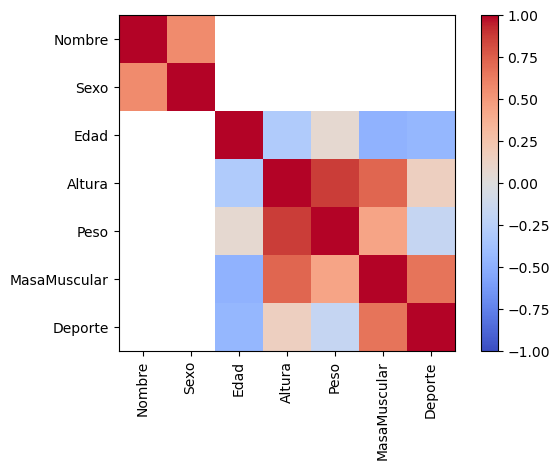

In [20]:
plot_correlacion(cor)

Como resumen, este trabajo muestra la aplicación de varias funciones básicas para la gestión de datasets y su tratamiento en lenguaje Python, siendo todas ellas de implementación propia, aunque se han apoyado en librerias externas en el apartado de la representación gráfica, como matplotlib y para la organización de datos (pandas). 